# Lab 8


## Setup for SUSY Dataset

Use the SUSY dataset for the rest of this lab. Here is a basic setup. It reads the full file you downloaded in Lab 7 (5 million rows, about 760 MB in memory once loaded). If your computer struggles, read `../Lab.7/SUSY-small.csv` instead (the first 500,000 rows) and divide the sample sizes below by ten.

`RawNames` are the 8 quantities measured directly; `FeatureNames` are the 10 derived from them, which the physicists designed to separate signal from background. You will need both in Exercise 3.

In [2]:
# Imported the libraries needed for the lab.
# Pandas handles the data, NumPy handles calculations,
# matplotlib creates graphs, and sklearn trains models.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.base import clone

VarNames = [
    "signal", "l_1_pT", "l_1_eta", "l_1_phi",
    "l_2_pT", "l_2_eta", "l_2_phi",
    "MET", "MET_phi", "MET_rel", "axial_MET",
    "M_R", "M_TR_2", "R", "MT2", "S_R",
    "M_Delta_R", "dPhi_r_b", "cos_theta_r1"
]

RawNames = VarNames[1:9]
FeatureNames = VarNames[9:]

print("Libraries imported successfully.")
print("Raw variables:", len(RawNames))
print("Derived variables:", len(FeatureNames))

Libraries imported successfully.
Raw variables: 8
Derived variables: 10


In [5]:
# Load the smaller SUSY dataset for Lab 8

import pandas as pd
from pathlib import Path

filename = Path("../Lab.7/SUSY-small.csv")

df = pd.read_csv(
    filename,
    header=None,
    names=VarNames,
    nrows=120000
)

print("Total observations:", len(df))
print("Number of columns:", len(df.columns))
print(df["signal"].value_counts())

Total observations: 120000
Number of columns: 19
signal
0.0    64862
1.0    55138
Name: count, dtype: int64


## Scikit-Learn

[Scikit-learn](https://scikit-learn.org) is a rich python library for data science, including machine learning. For example, we can build a Fisher Discriminant (aka Linear Discriminant Analysis, or LDA). 

### Exercise 1: Install Scikit-Learn

`scikit-learn` is in the course `requirements.txt`, so it should already be in your environment: check that `import sklearn` works. If it doesn't, follow the [Installation Instructions](https://scikit-learn.org/stable/install.html).

In [1]:
# Exercise 1
# I imported scikit-learn to check that it is installed.


import sklearn

print("Scikit-learn version:", sklearn.__version__)
print("Scikit-learn imported successfully.")



Scikit-learn version: 1.9.1
Scikit-learn imported successfully.


In [4]:

# Verify that scikit-learn works

import sklearn

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

print("Scikit-learn version:", sklearn.__version__)

# Create an LDA classifier
model = LinearDiscriminantAnalysis()

print("LDA classifier created successfully!")

assert model is not None

print("\nExercise 1 tests passed!")


Scikit-learn version: 1.9.1
LDA classifier created successfully!

Exercise 1 tests passed!


### Exercise 2: Read About Classifiers

#### Part a
Scikit-learn offers an impressively comprehensive list of machine learning algorithms. Browse through [scikit-learn's documentation](https://scikit-learn.org/stable/index.html). You'll note the algorithms are organized into classification, regression, clustering, dimensionality reduction, model selection, and preprocessing. Browse through the list of [classification algorithms](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning). 

#### Part b
Note scikit-learn's documentation is rather comprehensive. The documentation on [linear models](https://scikit-learn.org/stable/modules/linear_model.html) shows how classification problems are setup. Read about the first few methods and try to comprehend the example codes. Skim the rest of the document.

#### Part c
Read through the [LDA Documentation](https://scikit-learn.org/stable/modules/lda_qda.html).


In [10]:

# Lab 8 - Check required Python libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import tabulate

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-Learn:", sklearn.__version__)

print("\nAll required libraries imported successfully!")


Pandas: 3.1.1
NumPy: 2.5.5
Scikit-Learn: 1.9.1

All required libraries imported successfully!


### Exercise 3: Training a Classifier

Let's repeat what we did by hand in the previous lab (Lab 7, Exercise 8) using scikit-learn. We'll use an LDA classifier, which we can instantiate as follows:

In [11]:
import sklearn.discriminant_analysis as DA
Fisher=DA.LinearDiscriminantAnalysis()






In [12]:

# Lab 8 - Exercise 3
# Check whether the SUSY dataset is available

from pathlib import Path

small_file = Path("../Lab.7/SUSY-small.csv")
full_file = Path("../Lab.7/SUSY.csv")

print("Small dataset available:", small_file.exists())
print("Full dataset available:", full_file.exists())


Small dataset available: True
Full dataset available: False


As discussed in the lecture, to properly formulate our problem, we'll have to:

* Define the inputs (X) vs outputs (Y)
* Designate training vs testing samples (in order to get an unbiased assessment of the performance of machine learning algorithms)

For example, here we'll use 4M events for training and the remainder for testing.

I separated the input variables from the signal labels and used 80% of the data for training and 20% for testing. I used stratify to keep similar proportions of signal and background events in both datasets.

In [7]:
# Exercise 3


from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

X = df[VarNames[1:]]
y = df["signal"].astype(int)

X_Train, X_Test, y_Train, y_Test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_Train))
print("Testing observations:", len(X_Test))

Training observations: 96000
Testing observations: 24000


We can train the classifier as follows:

In [8]:
# I created a Linear Discriminant Analysis classifier.
# trained the model using the training dataset and then calculated scores for both training
# and testing data to compare their performance.

Fisher = LinearDiscriminantAnalysis()

Fisher.fit(X_Train, y_Train)

train_scores = Fisher.decision_function(X_Train)
test_scores = Fisher.decision_function(X_Test)

print("LDA classifier trained successfully.")
print("Training score count:", len(train_scores))
print("Testing score count:", len(test_scores))

LDA classifier trained successfully.
Training score count: 96000
Testing score count: 24000


We can plot the output, comparing signal and background:

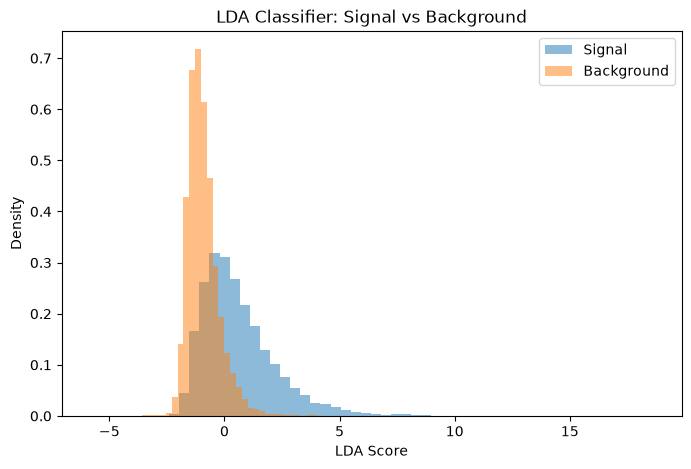

In [9]:
# I plotted the classifier scores for signal and background events in the testing dataset.
# This helps me see how well the model separates the two types of events.

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    test_scores[y_Test.to_numpy() == 1],
    bins=50,
    density=True,
    alpha=0.5,
    label="Signal"
)

plt.hist(
    test_scores[y_Test.to_numpy() == 0],
    bins=50,
    density=True,
    alpha=0.5,
    label="Background"
)

plt.xlabel("LDA Score")
plt.ylabel("Density")
plt.title("LDA Classifier: Signal vs Background")
plt.legend()
plt.show()

#### Part a

Compare the ROC curves computed on the test and on the training samples, in a single plot. Do you see a bias? (Use `Fisher.decision_function` on each sample, and `roc_curve` as in Exercise 5.)

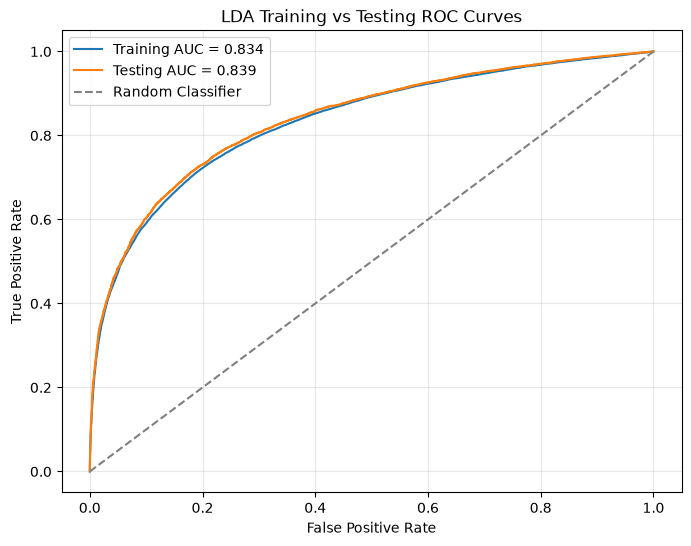

Training AUC: 0.8339
Testing AUC: 0.8394
AUC Difference: -0.0056


In [10]:


from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Calculate ROC values for training data
fpr_train, tpr_train, _ = roc_curve(y_Train, train_scores)

# Calculate ROC values for testing data
fpr_test, tpr_test, _ = roc_curve(y_Test, test_scores)

# Calculate the area under each ROC curve
auc_train = auc(fpr_train, tpr_train)
auc_test = auc(fpr_test, tpr_test)

# Create the comparison graph
plt.figure(figsize=(8, 6))

plt.plot(fpr_train, tpr_train,
         label=f"Training AUC = {auc_train:.3f}")

plt.plot(fpr_test, tpr_test,
         label=f"Testing AUC = {auc_test:.3f}")

# Add a reference line for random classification
plt.plot([0, 1], [0, 1], "--",
         color="gray", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("LDA Training vs Testing ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Display results
print("Training AUC:", round(auc_train, 4))
print("Testing AUC:", round(auc_test, 4))
print("AUC Difference:", round(auc_train - auc_test, 4))


Training AUC was 0.8339 and testing AUC was 0.8394 They both are very similar, and 
that might suggest the classifier performed consistently on both datasets.
So there is little evidence for overfitting. And from my understanding AUC measures
how well the classifier distinguishes between signal and background events.


#### Part b

Train three Fisher discriminants, using as input (1) only the raw quantities (`RawNames`), (2) only the derived features (`FeatureNames`), and (3) all 18. Compare their ROC curves, computed on the test sample, in a single plot. Which inputs carry the separation?

I trained three LDA models using different feature groups. The first model uses the 8 raw measurements. The second model uses the 10 derived features. The third model uses all 18 variables together. I compared their ROC curves and AUC scores, to see which group separates signal and background best.

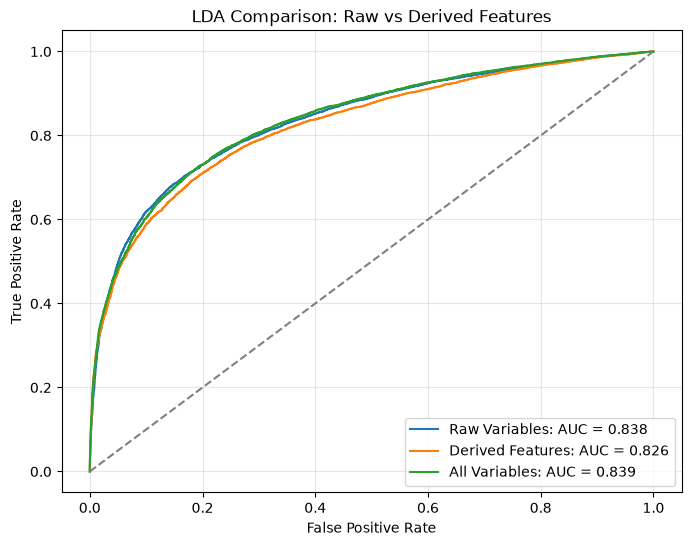

Raw Variables AUC: 0.8379
Derived Features AUC: 0.8264
All Variables AUC: 0.8394

Best feature group: All Variables


In [17]:

# Exercise 3b

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

feature_groups = {
    "Raw Variables": RawNames,
    "Derived Features": FeatureNames,
    "All Variables": VarNames[1:]
}

lda_results = {}

plt.figure(figsize=(8, 6))

for name, columns in feature_groups.items():

    # Create and train a separate model
    model = LinearDiscriminantAnalysis()
    model.fit(X_Train[columns], y_Train)

    # Calculate scores using the testing data
    scores = model.decision_function(X_Test[columns])

    # Calculate ROC and AUC
    fpr, tpr, thresholds = roc_curve(y_Test, scores)
    roc_auc = auc(fpr, tpr)

    lda_results[name] = roc_auc

    plt.plot(
        fpr, tpr,
        label=f"{name}: AUC = {roc_auc:.3f}"
    )

plt.plot([0, 1], [0, 1], "--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("LDA Comparison: Raw vs Derived Features")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Display results
for name, score in lda_results.items():
    print(name, "AUC:", round(score, 4))

best_group = max(lda_results, key=lda_results.get)
print("\nBest feature group:", best_group)


### Exercise 4: Comparing Techniques

#### Part a
Select 3 different classifiers from the techniques listed [here](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning) to compare. Note that you can use the multi-layer perceptron to build a deep network, though training may be prohibitively slow. So avoid this technique.

#### Part b

Write a function that takes an instantiated classifier and performs the comparison from Exercise 3b. Use the function on each of the classifiers you chose in part a.

#### Part c

Use the best method from part b to compute the maximal significance $\sigma_S= \frac{N_S}{\sqrt{N_S+N_B}}$ for the four scenarios in Lab 7 (Exercise 5.3), choosing the cut on the classifier's output that maximizes it.

Exercise 4a and 4b, I selected three machine learning classifiers to compare and used the same training and testing data for each model.
I created a function that trains each classifier using raw variables, derived features, and all 18 variables.
I compared the ROC curves and AUC scores to determine which model performed best on the testing dataset.


Training: Naive Bayes


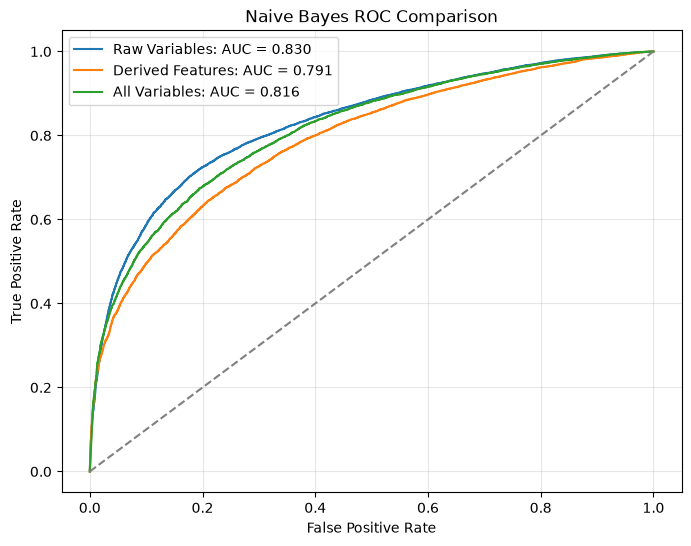


Training: Logistic Regression


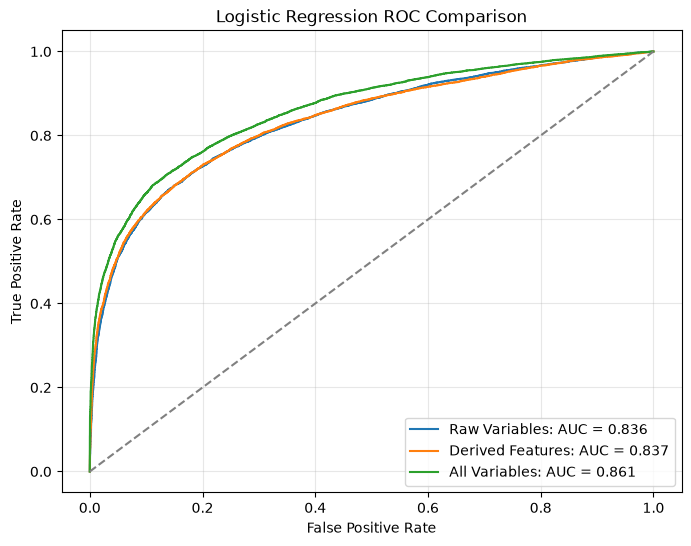


Training: Decision Tree


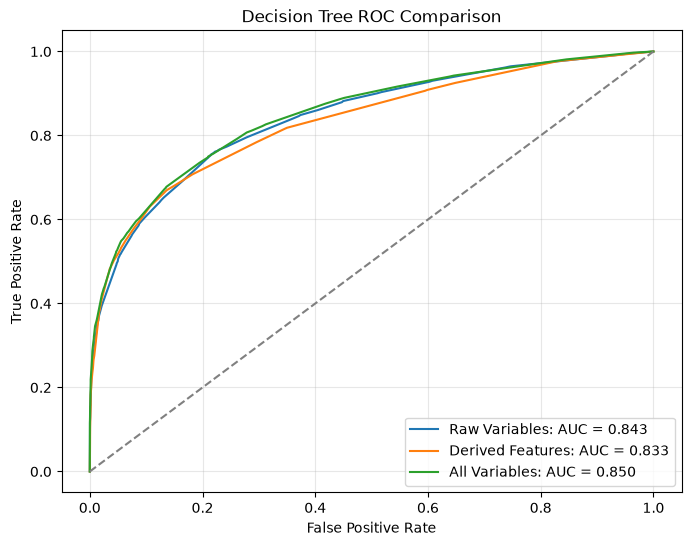


Best classifier: Logistic Regression
Best feature group: All Variables
Best AUC: 0.8614


In [18]:
# EX4 A and B

from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.metrics import roc_curve, auc

import matplotlib.pyplot as plt

# Create the three classifiers
classifiers = {
    "Naive Bayes": GaussianNB(),

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=300, random_state=42)
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=100,
        random_state=42
    )
}

# Function to compare a classifier with different feature groups
def compare_classifiers(model, model_name):

    results = {}

    plt.figure(figsize=(8, 6))

    for group_name, columns in feature_groups.items():

        # Train a new model for this feature group
        trained_model = clone(model)
        trained_model.fit(X_Train[columns], y_Train)

        # Predict signal probabilities on the testing dataset
        scores = trained_model.predict_proba(
            X_Test[columns]
        )[:, 1]

        # Calculate ROC and AUC
        fpr, tpr, thresholds = roc_curve(y_Test, scores)
        roc_auc = auc(fpr, tpr)

        # Store results to use in later exercises
        results[group_name] = {
            "model": trained_model,
            "columns": columns,
            "scores": scores,
            "auc": roc_auc
        }

        plt.plot(
            fpr, tpr,
            label=f"{group_name}: AUC = {roc_auc:.3f}"
        )

    plt.plot([0, 1], [0, 1], "--", color="gray")

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(model_name + " ROC Comparison")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    return results


# Test all three classifiers
comparison_results = {}

for name, model in classifiers.items():
    print("\nTraining:", name)

    comparison_results[name] = compare_classifiers(
        model, name
    )


# Find the model with the highest AUC
best_auc = -1

for model_name, groups in comparison_results.items():
    for group_name, result in groups.items():

        if result["auc"] > best_auc:
            best_auc = result["auc"]
            best_name = model_name
            best_group = group_name
            best_result = result

print("\nBest classifier:", best_name)
print("Best feature group:", best_group)
print("Best AUC:", round(best_auc, 4))


In [19]:
# EX 4C


# I used the best classifier from Exercise 4b and tested different classification thresholds
# to find the highest statistical significance.

# I repeated the calculation for four different numbers of expected signal and background events.

import numpy as np
import pandas as pd
from sklearn.metrics import roc_curve

# Get the scores from the best classifier
best_scores = best_result["scores"]

# Calculate true and false positive rates
fpr, tpr, thresholds = roc_curve(
    y_Test, best_scores, drop_intermediate=False
)

# Signal and background scenarios
scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

best_cuts = []

for ns, nb in scenarios:

    # Calculate expected events after each threshold
    signal_after = ns * tpr
    background_after = nb * fpr

    # Calculate significance for each threshold
    total = signal_after + background_after

    significance = np.divide(
        signal_after,
        np.sqrt(total),
        out=np.zeros_like(total),
        where=total > 0
    )

    # Find the threshold with the highest significance
    best_index = np.argmax(significance)

    best_cuts.append({
        "Signal": ns,
        "Background": nb,
        "Threshold": thresholds[best_index],
        "TPR": tpr[best_index],
        "FPR": fpr[best_index],
        "Max Significance": significance[best_index]
    })

# Display the results
significance_table = pd.DataFrame(best_cuts)

print("Best classifier:", best_name)
print("Best feature group:", best_group)
print()
print(significance_table.round(4).to_string(index=False))


Best classifier: Logistic Regression
Best feature group: All Variables

 Signal  Background  Threshold    TPR    FPR  Max Significance
     10         100     0.7845 0.4674 0.0244            1.7521
    100        1000     0.7845 0.4674 0.0244            5.5405
   1000       10000     0.7845 0.4674 0.0244           17.5205
  10000      100000     0.7845 0.4674 0.0244           55.4048


### Exercise 5: Metrics

Scikit-learn provides methods for computing the FPR, TPR, ROC, AUC metrics. For example:

In [ ]:
from sklearn.metrics import roc_curve, auc
fpr, tpr, _ = roc_curve(y_Test, Fisher.decision_function(X_Test))

roc_auc = auc(fpr, tpr)

plt.plot(fpr,tpr,color='darkorange',label='ROC curve (area = %0.2f)' % roc_auc)
plt.legend(loc="lower right")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.show()


#### Part a
TPR/FPR/ROC/AUC are one way of assessing the quality of a classifier. Read about [Precision and Recall](https://en.wikipedia.org/wiki/Precision_and_recall), [Accuracy](https://en.wikipedia.org/wiki/Accuracy_and_precision), and [F-score](https://en.wikipedia.org/wiki/F-score).

#### Part b
Look through [model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html#) documentation. Using scikit-learn's tools, compute TPR, FPR, ROC, AUC, Precision, Recall, F1 score, and accuracy for the method you selected in Exercise 4c and each scenario. Make a nice table, which also includes the maximal significance. 


I used the best classifier from Exercise 4 and calculated precision, recall, F1, accuracy, and AUC.
I also used a confusion matrix to find TPR, FPR and adjusted the sample weights to represent the four different signal and background scenarios.

In [20]:

# EX 5b


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score,
    roc_curve
)

# Get the actual labels and classifier scores
actual = y_Test.to_numpy()
scores = best_result["scores"]

results = []

for cut in best_cuts:

    ns = cut["Signal"]
    nb = cut["Background"]
    threshold = cut["Threshold"]

    # Predict signal when the score reaches the cutoff
    predicted = (scores >= threshold).astype(int)

    # Weight each class according to the scenario
    weights = np.where(
        actual == 1,
        ns / np.sum(actual == 1),
        nb / np.sum(actual == 0)
    )

    # Calculate the expected confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        actual,
        predicted,
        sample_weight=weights,
        labels=[0, 1]
    ).ravel()

    # Calculate TPR and FPR
    tpr = tp / (tp + fn) if tp + fn > 0 else 0
    fpr = fp / (fp + tn) if fp + tn > 0 else 0

    # Use scikit-learn to calculate the metrics
    precision = precision_score(
        actual, predicted,
        sample_weight=weights,
        zero_division=0
    )

    recall = recall_score(
        actual, predicted,
        sample_weight=weights,
        zero_division=0
    )

    f1 = f1_score(
        actual, predicted,
        sample_weight=weights,
        zero_division=0
    )

    accuracy = accuracy_score(
        actual, predicted,
        sample_weight=weights
    )

    roc_auc = roc_auc_score(
        actual, scores,
        sample_weight=weights
    )

    results.append({
        "Signal": ns,
        "Background": nb,
        "TPR": tpr,
        "FPR": fpr,
        "ROC AUC": roc_auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Accuracy": accuracy,
        "Max Significance": cut["Max Significance"]
    })

# Display the results in a table
metrics_df = pd.DataFrame(results)

print("Best classifier:", best_name)
print("Best feature group:", best_group)
print()
print(metrics_df.round(4).to_string(index=False))


Best classifier: Logistic Regression
Best feature group: All Variables

 Signal  Background    TPR    FPR  ROC AUC  Precision  Recall  F1 Score  Accuracy  Max Significance
     10         100 0.4674 0.0244   0.8614     0.6567  0.4674    0.5461    0.9294            1.7521
    100        1000 0.4674 0.0244   0.8614     0.6567  0.4674    0.5461    0.9294            5.5405
   1000       10000 0.4674 0.0244   0.8614     0.6567  0.4674    0.5461    0.9294           17.5205
  10000      100000 0.4674 0.0244   0.8614     0.6567  0.4674    0.5461    0.9294           55.4048


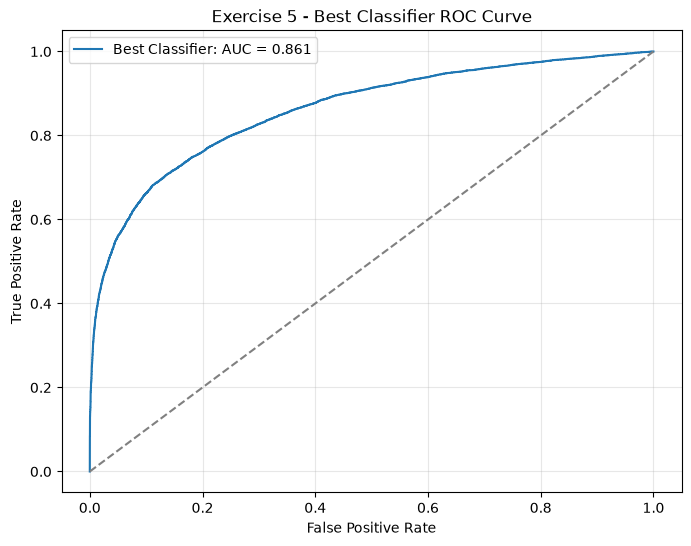

In [21]:
# I plotted the ROC curve for the best classifier.
# The curve shows how the true positive rate changes as the false positive rate increases.

fpr, tpr, thresholds = roc_curve(actual, scores)

roc_area = roc_auc_score(actual, scores)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr, tpr,
    label=f"Best Classifier: AUC = {roc_area:.3f}"
)

plt.plot([0, 1], [0, 1], "--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Exercise 5 - Best Classifier ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()